LAB ASSIGNMENT 9

In [1]:
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, callbacks, regularizers
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)
from IPython.display import display

FRAMES = 32
SIZE = 112
CACHE_FRAMES = 64


Task 1: Data Acquisition and Exploration

In [2]:
DATA_DIR = Path('/kaggle/input/datasets/shahliza27/ur-fall-detection-dataset/UR_fall_detection_dataset_cam0_rgb')
records = []

for folder in sorted(DATA_DIR.iterdir()):
    records.append({
        'sequence': folder.name,
        'path': str(folder),
        'label': int(folder.name.startswith('fall')),
        'frames': len(list(folder.glob('*.png')))
    })

df = pd.DataFrame(records)
display(df.head())
print(df['label'].value_counts().rename(index={0: 'Normal', 1: 'Fall'}))

,sequence,path,label,frames
0,adl-01-cam0-rgb,/kaggle/input/datasets/shahliza27/ur-fall-dete...,0,150
1,adl-02-cam0-rgb,/kaggle/input/datasets/shahliza27/ur-fall-dete...,0,180
2,adl-03-cam0-rgb,/kaggle/input/datasets/shahliza27/ur-fall-dete...,0,180
3,adl-04-cam0-rgb,/kaggle/input/datasets/shahliza27/ur-fall-dete...,0,150
4,adl-05-cam0-rgb,/kaggle/input/datasets/shahliza27/ur-fall-dete...,0,180


label
Normal    40
Fall      30
Name: count, dtype: int64


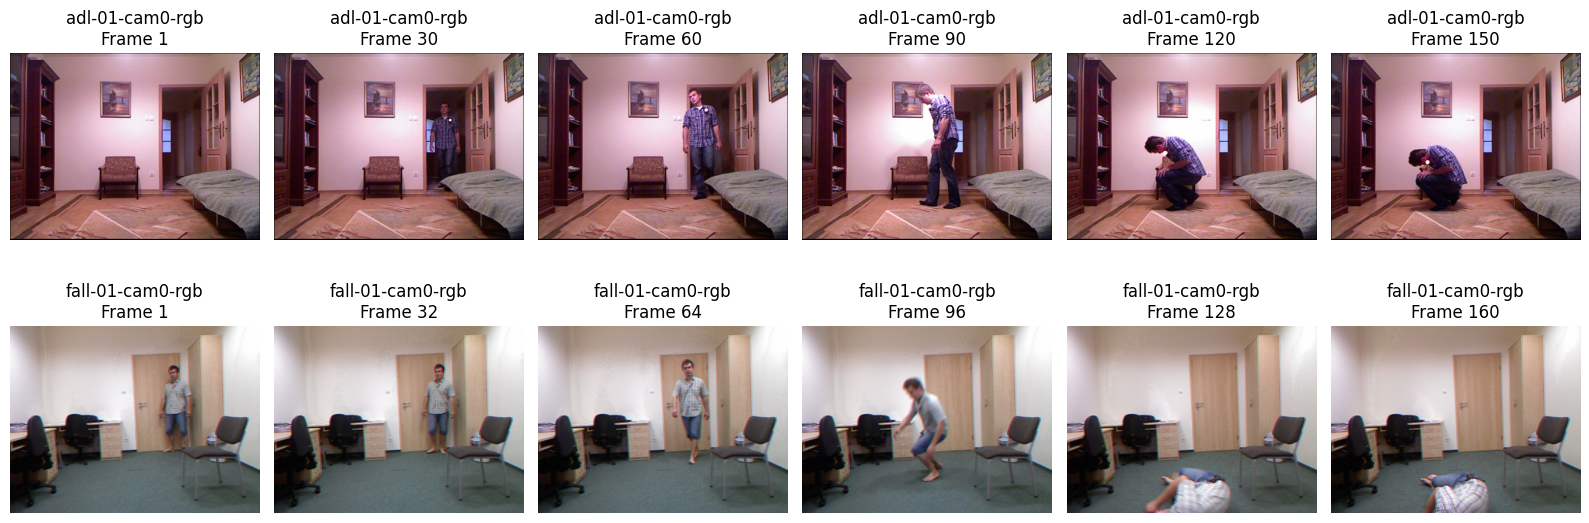

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for label in [0, 1]:
    row = df[(df['label'] == label) & (df['frames'] > 0)].iloc[0]
    files = sorted(Path(row['path']).glob('*.png'),
                   key=lambda p: int(p.stem.split('-')[-1]))
    indices = np.linspace(0, len(files) - 1, 6).astype(int)

    for column, index in enumerate(indices):
        frame = cv2.imread(str(files[index]))
        if frame is not None:
            axes[label, column].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        axes[label, column].set_title(f"{row['sequence']}\nFrame {index + 1}")
        axes[label, column].axis('off')

plt.tight_layout()
plt.show()

Task 2: Data Preprocessing

Check corrupted frames, convert to RGB, and resize

Exclude sequences containing unreadable frames. Keep 48 chronological frames temporarily so temporal jittering can later select different 16-frame clips. Repeat frames if a sequence is shorter than 48 frames.

In [4]:
# Check every frame using four concurrent file readers.
clip_bank = []
valid_rows = []
bad_sequences = []

for i, row in df.iterrows():
    files = sorted(Path(row['path']).glob('*.png'),
                   key=lambda p: int(p.stem.split('-')[-1]))
    if len(files) == 0:
        bad_sequences.append(row['sequence'])
        continue

    indices = np.linspace(0, len(files) - 1, CACHE_FRAMES).round().astype(int)
    selected = set(indices)
    saved_frames = {}
    corrupted = False

    with ThreadPoolExecutor(max_workers=4) as reader:
        for index, frame in enumerate(reader.map(cv2.imread, [str(p) for p in files])):
            if frame is None:
                corrupted = True
                break
            if index in selected:
                frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
                saved_frames[index] = cv2.resize(frame, (SIZE, SIZE))
    if corrupted:
        bad_sequences.append(row['sequence'])
    else:
        clip_bank.append(np.stack([saved_frames[k] for k in indices]))
        valid_rows.append(i)

clips = np.stack(clip_bank)
df = df.loc[valid_rows].reset_index(drop=True)
labels = df['label'].to_numpy()
del clip_bank
print('Excluded sequences:', bad_sequences)
print('Cached tensor shape:', clips.shape)


Excluded sequences: []
Cached tensor shape: (70, 64, 112, 112, 3)


Split before augmentation. For 70 valid sequences, the approximate 70/15/15 split gives 49 training, 10 validation, and 11 test sequences.

In [5]:
train_idx, remaining_idx = train_test_split(
    np.arange(len(df)), test_size=0.30, stratify=labels
)
val_idx, test_idx = train_test_split(
    remaining_idx, test_size=0.50, stratify=labels[remaining_idx]
)

print('Training sequences:', len(train_idx))
print('Validation sequences:', len(val_idx))
print('Testing sequences:', len(test_idx))

Training sequences: 49
Validation sequences: 10
Testing sequences: 11


For each training sequence, use one original clip and four augmented clips. Apply temporal jittering, horizontal flipping, and random cropping only to training data. Keep the same flip and crop across every frame of a clip. Normalize inputs to [0, 1].

In [6]:
fixed_indices = np.linspace(0, CACHE_FRAMES - 1, FRAMES).round().astype(int)
X_train, y_train = [], []

for i in train_idx:
    # One original clip and four augmented clips per training sequence.
    for version in range(5):
        indices = fixed_indices
        if version > 0:
            start = int(np.random.randint(0, 7))
            end = CACHE_FRAMES - 1 - int(np.random.randint(0, 7))
            indices = np.linspace(start, end, FRAMES).round().astype(int)

        clip = clips[i, indices].copy()

        if version > 0:
            if np.random.rand() < 0.5:
                clip = clip[:, :, ::-1, :]
            crop_size = int(np.random.uniform(0.90, 1.0) * SIZE)
            top, left = np.random.randint(0, SIZE - crop_size + 1, size=2)
            clip = np.stack([
                cv2.resize(frame[top:top + crop_size, left:left + crop_size],
                           (SIZE, SIZE)) for frame in clip
            ])

        X_train.append(clip)
        y_train.append(labels[i])

# Final input shape: (sequences, frames, height, width, channels).
X_train = np.asarray(X_train, dtype=np.float32) / 255.0
y_train = np.asarray(y_train)
X_val = clips[val_idx][:, fixed_indices].astype(np.float32) / 255.0
X_test = clips[test_idx][:, fixed_indices].astype(np.float32) / 255.0
y_val = labels[val_idx]
y_test = labels[test_idx]

print('Training:', X_train.shape)
print('Validation:', X_val.shape)
print('Testing:', X_test.shape)
print('Pixel range:', X_train.min(), 'to', X_train.max())

Training: (245, 32, 112, 112, 3)
Validation: (10, 32, 112, 112, 3)
Testing: (11, 32, 112, 112, 3)
Pixel range: 0.0 to 1.0


Handle class imbalance with weighted loss

In [7]:
weights = compute_class_weight(
    class_weight='balanced', classes=np.array([0, 1]), y=y_train
)
class_weights = {0: float(weights[0]), 1: float(weights[1])}
print('Class weights:', class_weights)

Class weights: {0: 0.875, 1: 1.1666666666666667}


Task 3: Model Training and Basic Evaluation

In [8]:
model = models.Sequential([
    layers.Input(shape=(FRAMES, SIZE, SIZE, 3)),

    layers.Conv3D(16, 3, strides=(1, 2, 2), padding='same',
                  use_bias=False, kernel_regularizer=regularizers.l2(1e-4)),
    layers.GroupNormalization(groups=4),
    layers.Activation('relu'),
    layers.MaxPooling3D(pool_size=(1, 2, 2)),
    layers.SpatialDropout3D(0.1),

    layers.Conv3D(32, 3, padding='same', use_bias=False,
                  kernel_regularizer=regularizers.l2(1e-4)),
    layers.GroupNormalization(groups=4),
    layers.Activation('relu'),
    layers.MaxPooling3D(pool_size=(2, 2, 2)),
    layers.SpatialDropout3D(0.2),

    layers.Conv3D(64, 3, padding='same', use_bias=False,
                  kernel_regularizer=regularizers.l2(1e-4)),
    layers.GroupNormalization(groups=4),
    layers.Activation('relu'),
    layers.MaxPooling3D(pool_size=(2, 2, 2)),

    layers.GlobalAveragePooling3D(),
    layers.Dense(64, activation='relu',
                 kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer=Adam(learning_rate=0.0003),
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.summary()

I0000 00:00:1793553608.986528      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793553608.990383      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 32, 56, 56, 16) │         1,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization             │ (None, 32, 56, 56, 16) │            32 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 56, 56, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 32, 28, 28, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout3d               │ (None, 32, 28, 28, 16) │             0 │
│ (SpatialDropout3D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 32, 28, 28, 32) │        13,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_1           │ (None, 32, 28, 28, 32) │            64 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 28, 28, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 16, 14, 14, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout3d_1             │ (None, 16, 14, 14, 32) │             0 │
│ (SpatialDropout3D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 16, 14, 14, 64) │        55,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ group_normalization_2           │ (None, 16, 14, 14, 64) │           128 │
│ (GroupNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 14, 14, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 8, 7, 7, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,865 (292.44 KB)

 Trainable params: 74,865 (292.44 KB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [9]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    start_from_epoch=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=80,
    batch_size=8,
    class_weight=class_weights,
    callbacks=[reduce_lr, early_stop],
    shuffle=True,
    verbose=2
)


Epoch 1/80


I0000 00:00:1793553624.742399     428 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


31/31 - 21s - 669ms/step - accuracy: 0.5347 - loss: 0.7632 - val_accuracy: 0.6000 - val_loss: 0.6900 - learning_rate: 3.0000e-04
Epoch 2/80
31/31 - 2s - 50ms/step - accuracy: 0.6163 - loss: 0.6422 - val_accuracy: 0.8000 - val_loss: 0.5041 - learning_rate: 3.0000e-04
Epoch 3/80
31/31 - 2s - 48ms/step - accuracy: 0.6898 - loss: 0.5484 - val_accuracy: 0.8000 - val_loss: 0.4861 - learning_rate: 3.0000e-04
Epoch 4/80
31/31 - 1s - 48ms/step - accuracy: 0.6898 - loss: 0.5705 - val_accuracy: 0.8000 - val_loss: 0.4748 - learning_rate: 3.0000e-04
Epoch 5/80
31/31 - 2s - 49ms/step - accuracy: 0.7061 - loss: 0.5677 - val_accuracy: 0.6000 - val_loss: 0.6112 - learning_rate: 3.0000e-04
Epoch 6/80
31/31 - 2s - 49ms/step - accuracy: 0.7143 - loss: 0.5227 - val_accuracy: 0.8000 - val_loss: 0.4119 - learning_rate: 3.0000e-04
Epoch 7/80
31/31 - 2s - 49ms/step - accuracy: 0.7592 - loss: 0.4841 - val_accuracy: 0.8000 - val_loss: 0.4127 - learning_rate: 3.0000e-04
Epoch 8/80
31/31 - 2s - 49ms/step - accurac

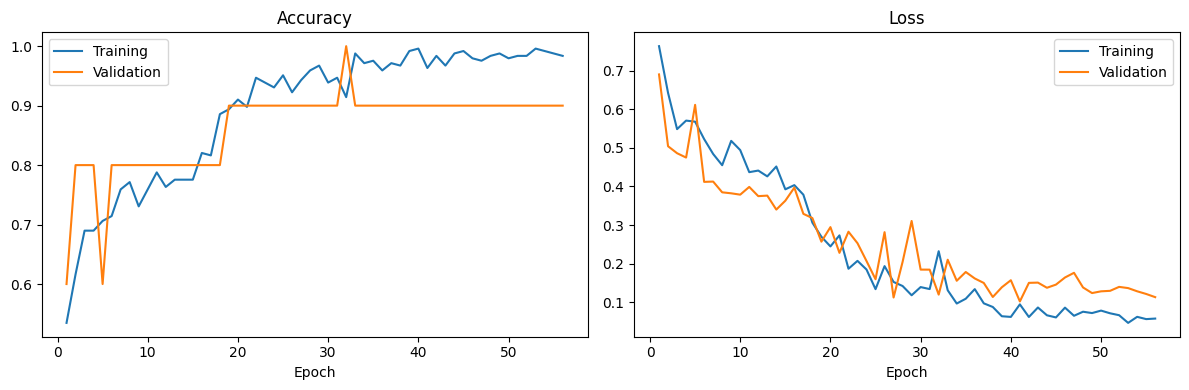

In [10]:
epochs = np.arange(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history['accuracy'], label='Training')
axes[0].plot(epochs, history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy')

axes[1].plot(epochs, history.history['loss'], label='Training')
axes[1].plot(epochs, history.history['val_loss'], label='Validation')
axes[1].set_title('Loss')

for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()

plt.tight_layout()
plt.show()

Accuracy, precision, recall, F1-score, and AUROC

Treat Fall as the positive class. Keep the classification threshold at 0.5 and calculate AUROC from probabilities. Evaluate this selected model on the test set without choosing settings from the test results.

In [11]:
probabilities = model.predict(X_test, batch_size=8, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)

scores = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score', 'AUROC'],
    'Value': [accuracy_score(y_test, predictions),
              precision_score(y_test, predictions, zero_division=0),
              recall_score(y_test, predictions, zero_division=0),
              f1_score(y_test, predictions, zero_division=0),
              roc_auc_score(y_test, probabilities)]
})
display(scores.round(4))
print(classification_report(y_test, predictions, labels=[0, 1],
                            target_names=['Normal', 'Fall'], zero_division=0))

,Metric,Value
0,Accuracy,0.7273
1,Precision,0.6250
2,Recall,1.0000
3,F1-score,0.7692
4,AUROC,1.0000


              precision    recall  f1-score   support

      Normal       1.00      0.50      0.67         6
        Fall       0.62      1.00      0.77         5

    accuracy                           0.73        11
   macro avg       0.81      0.75      0.72        11
weighted avg       0.83      0.73      0.71        11



Confusion matrix and ROC curve

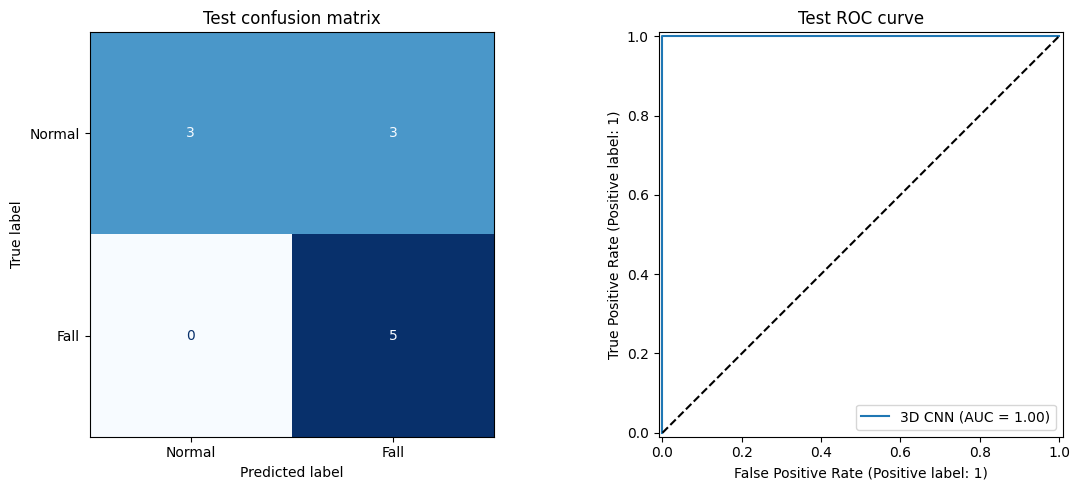

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=[0, 1], display_labels=['Normal', 'Fall'],
    cmap='Blues', colorbar=False, ax=axes[0]
)
axes[0].set_title('Test confusion matrix')
RocCurveDisplay.from_predictions(y_test, probabilities, ax=axes[1], name='3D CNN')
axes[1].plot([0, 1], [0, 1], 'k--')
axes[1].set_title('Test ROC curve')
plt.tight_layout()
plt.show()

Identify false positives and false negatives

In [13]:
results = pd.DataFrame({
    'Sequence': df.iloc[test_idx]['sequence'].to_numpy(),
    'Actual': y_test,
    'Predicted': predictions,
    'Fall probability': probabilities
})
results['Outcome'] = 'Correct'
results.loc[(y_test == 0) & (predictions == 1), 'Outcome'] = 'False positive'
results.loc[(y_test == 1) & (predictions == 0), 'Outcome'] = 'False negative'
display(results)
print(results['Outcome'].value_counts())

,Sequence,Actual,Predicted,Fall probability,Outcome
0,fall-16-cam0-rgb,1,1,0.990706,Correct
1,fall-13-cam0-rgb,1,1,0.992825,Correct
2,adl-33-cam0-rgb,0,1,0.618261,False positive
3,fall-10-cam0-rgb,1,1,0.974082,Correct
4,fall-03-cam0-rgb,1,1,0.986301,Correct
5,adl-26-cam0-rgb,0,0,0.026400,Correct
6,adl-35-cam0-rgb,0,1,0.566545,False positive
7,fall-24-cam0-rgb,1,1,0.988768,Correct
8,adl-31-cam0-rgb,0,1,0.770981,False positive
9,adl-06-cam0-rgb,0,0,0.000081,Correct


Outcome
Correct           8
False positive    3
Name: count, dtype: int64


Inspect misclassified sequences

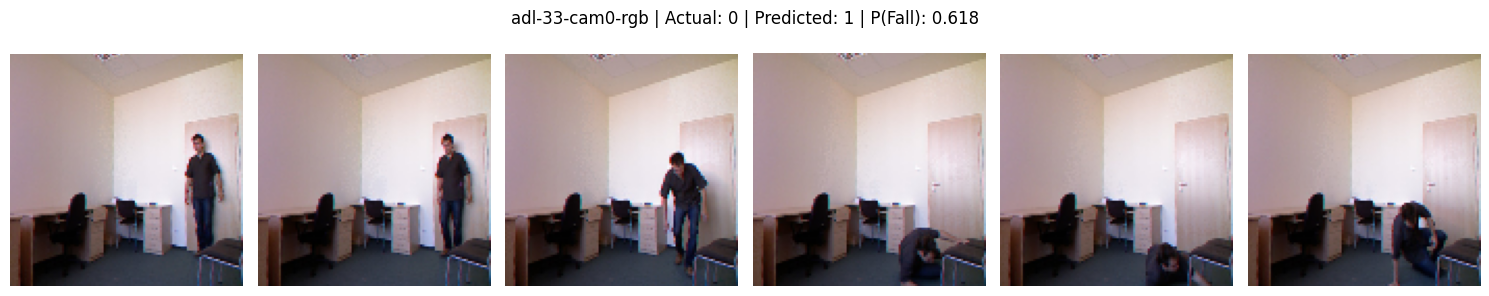

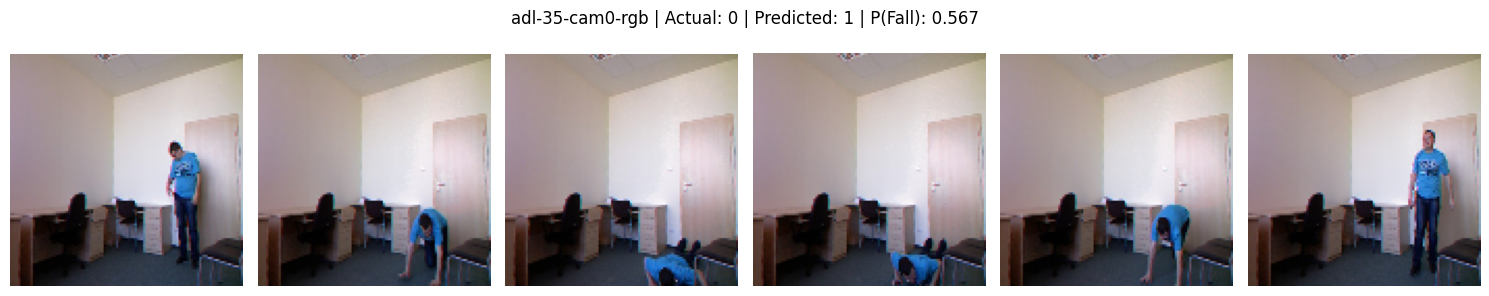

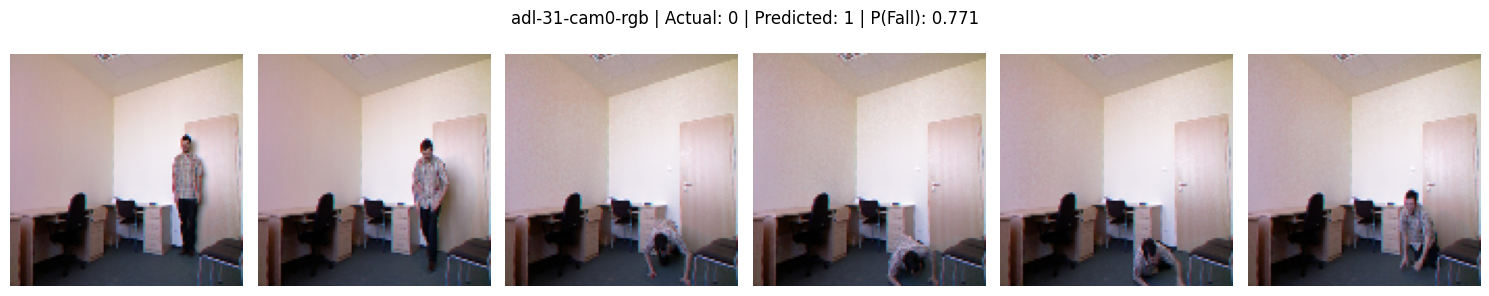

In [17]:
wrong_indices = np.flatnonzero(y_test != predictions)

if len(wrong_indices) == 0:
    print('No misclassified test sequences at the 0.5 threshold.')
else:
    for i in wrong_indices[:6]:
        fig, axes = plt.subplots(1, 6, figsize=(15, 3))
        for ax, frame_index in zip(axes, np.linspace(0, FRAMES - 1, 6).astype(int)):
            ax.imshow(X_test[i, frame_index])
            ax.axis('off')
        plt.suptitle(f"{results.iloc[i]['Sequence']} | Actual: {y_test[i]} | "
                     f"Predicted: {predictions[i]} | P(Fall): {probabilities[i]:.3f}")
        plt.tight_layout()
        plt.show()